# Task 2 – Paper Reproduction: Retrieval-Augmented Generation (RAG)

**Project 10 · Open-Domain Question Answering: From Lexical Retrieval to RAG**
**Dataset:** [`rag-datasets/rag-mini-wikipedia`](https://huggingface.co/datasets/rag-datasets/rag-mini-wikipedia)  
**Group:** 28  
**Name:** Nihar Ranjan Das  
**Roll.No:** 26AI60R20

### Objective
Reproduce the retrieve-then-generate pipeline of Lewis et al., *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks* (NeurIPS 2020), on the same passage index as Task 1, and compare it with the classical baseline.

### Pipeline
1. **Dense retrieval:** `sentence-transformers/all-MiniLM-L6-v2` embeddings, FAISS flat index, cosine similarity, top-k = 5.
2. **Generation:** an open instruction-tuned LLM (`Qwen/Qwen2.5-1.5B-Instruct`) is prompted with the top-5 passages (each truncated to 200 tokens) and the question; at most 64 new tokens, temperature 0 (greedy decoding).
3. **Evaluation:** Exact Match, token F1 and Recall@k for k ∈ {1, 3, 5, 10}, computed exactly as in Task 1.

### How to run
`Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all` (about 5 minutes, most of it answer generation).
- **Input:** `task1_results.json` from the Task 1 notebook, used only for the comparison in Section 8. It is picked up from the output folder; in Colab without Drive you are asked to upload it.
- **Output:** `task2_results.json` (dense rankings, answers, metrics, settings), `task2_generation_cache.json` and `task2_recall.png`, written to Google Drive (`USE_DRIVE = True`) or to `outputs/`.

Project run order: **Task 1 → Task 2 → Task 3**.

### Contents
1. Setup
2. Loading the data
3. Evaluation helpers
4. Dense retrieval
5. Answer generation
6. Evaluation
7. Error analysis: retrieval vs. generation
8. Comparison with Task 1
9. Additional checks
10. Recall@k plot and example predictions
11. Saving the results
12. Discussion
13. References

## 1. Setup
We install the libraries that are not pre-installed on Colab and define all settings in one place:

| Setting | Value | Meaning |
|---|---|---|
| `EMBED_MODEL` | `all-MiniLM-L6-v2` | sentence encoder for dense retrieval |
| `LLM_NAME` | `Qwen/Qwen2.5-1.5B-Instruct` | open instruction-tuned generator (fits a free T4 in float16) |
| `TOP_K` | 5 | passages given to the LLM |
| `PASSAGE_MAX_TOKENS` | 200 | each passage is truncated to 200 LLM tokens |
| `MAX_NEW_TOKENS` | 64 | maximum answer length |
| `KS`, `KEEP_N` | 1, 3, 5, 10 · 100 | Recall@k cut-offs · length of the saved ranking |
| `BATCH_SIZE` | 8 | prompts generated together; Task 3 reuses the same value |
| `DATASET_REVISION` | `1f9f3b5…` | fixed dataset version, identical in all notebooks |

`QUICK_TEST = True` runs everything on the first 40 questions, which is useful for checking that the notebook works before a full run.

In [1]:
%pip install -q datasets sentence-transformers faiss-cpu "transformers>=4.56" accelerate scikit-learn

import os, re, sys, json, string, collections, random, time, unicodedata, hashlib
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(42); np.random.seed(42)          # reproducibility

# Save outputs to Google Drive (Colab) so Notebook 3 can read them
USE_DRIVE = False           # False = no Google Drive (results stay in the local outputs/ folder)
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:        # running locally instead of Colab
    IN_COLAB = False
OUT = 'outputs'
if IN_COLAB and USE_DRIVE:
    try:
        drive.mount('/content/drive')
        OUT = '/content/drive/MyDrive/NLP_Project_2/outputs'
    except Exception as e:                   # e.g. authorisation declined or timed out
        print('Google Drive not mounted, using local outputs/ instead:', e)
os.makedirs(OUT, exist_ok=True)
print('Saving results to', OUT)

# ---- Settings required by the brief ----
EMBED_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
LLM_NAME = 'Qwen/Qwen2.5-1.5B-Instruct'      # open instruction-tuned LLM
TOP_K = 5                  # passages given to the LLM
PASSAGE_MAX_TOKENS = 200   # each passage truncated to 200 tokens
MAX_NEW_TOKENS = 64        # answer length limit
KS = [1, 3, 5, 10]         # Recall@k values to report
KEEP_N = 100               # length of saved ranking (Recall@10 + RRF fusion in Task 3)
DATASET_REVISION = '1f9f3b53fbc5995b85aab8e993504ad42c5f16f6'   # pinned dataset version (same in all notebooks)

# ---- Convenience settings ----
BATCH_SIZE = 8             # keep identical in Notebook 3: with fp16 + padding, a different batch size can
                           # change a few greedy answers (lower to 4 or 2 only for 'CUDA out of memory')
QUICK_TEST = False         # True = run on the first 40 questions only (to check the code works)

Saving results to outputs


## 2. Loading the data
We load the same 3,200 passages and 918 questions as in Task 1, with the same encoding repair of the 483 mis-encoded passages (see Task 1, Section 2). The passage list and its order are identical, so dense retrieval searches exactly the same index as BM25, without any re-chunking.

In [2]:
from datasets import load_dataset

corpus = load_dataset('rag-datasets/rag-mini-wikipedia', 'text-corpus', revision=DATASET_REVISION)
qa     = load_dataset('rag-datasets/rag-mini-wikipedia', 'question-answer', revision=DATASET_REVISION)

def fix_mojibake(s):
    # the dataset has UTF-8 text decoded as Latin-1, e.g. 'Lincolnâ\x80\x99s' instead of 'Lincoln’s'
    try:
        return s.encode('latin-1').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s                             # already clean - keep as is

passages    = [fix_mojibake(str(p)) for p in corpus['passages']['passage']]
passage_ids = list(corpus['passages']['id'])  # saved with the rankings, which are list positions
questions   = [fix_mojibake(str(q)) for q in qa['test']['question']]
answers     = [fix_mojibake(str(a)) for a in qa['test']['answer']]
if QUICK_TEST:
    questions, answers = questions[:40], answers[:40]

print(len(passages), 'passages |', len(questions), 'questions')
print('Example Q:', questions[0], '->', answers[0])

README.md:   0%|          | 0.00/719 [00:00<?, ?B/s]

data/passages.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B /  797kB            

data/passages.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating passages split: 0 examples [00:00, ? examples/s]

data/test.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B / 54.4kB            

data/test.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating test split: 0 examples [00:00, ? examples/s]

3200 passages | 918 questions
Example Q: Was Abraham Lincoln the sixteenth President of the United States? -> yes


## 3. Evaluation helpers
These are the same helpers as in Task 1: SQuAD-style normalisation, Exact Match, token F1, answer-string Recall@k and the yes/no rule. Using identical code makes the Task 1 and Task 2 numbers directly comparable.

In [3]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP

# every Unicode punctuation / symbol character (string.punctuation plus ’ – “ ” © ° ...), built once
PUNCT_TABLE = dict.fromkeys(i for i in range(sys.maxunicode + 1)
                            if unicodedata.category(chr(i))[0] in 'PS')

def normalize_answer(s):
    # SQuAD-style: lowercase, drop punctuation, drop articles (a/an/the), squash spaces
    s = str(s).lower().translate(PUNCT_TABLE)
    s = re.sub(r'\b(a|an|the)\b', ' ', s)
    return ' '.join(s.split())

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def f1_score(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    if len(p) == 0 or len(g) == 0:
        return float(p == g)
    same = sum((collections.Counter(p) & collections.Counter(g)).values())
    if same == 0:
        return 0.0
    precision, recall = same / len(p), same / len(g)
    return 2 * precision * recall / (precision + recall)

norm_passages = [f' {normalize_answer(p)} ' for p in passages]   # normalised once, reused below

def answer_in_passage(gold, passage):
    # True if the normalised gold answer appears as whole words inside the passage
    g = normalize_answer(gold)
    return len(g) > 0 and f' {g} ' in f' {normalize_answer(passage)} '

def first_hit_rank(ids, gold):
    # 1-based rank of the first passage in ids that contains the gold answer (inf if none)
    g = normalize_answer(gold)
    if not g:
        return np.inf
    return next((r for r, pid in enumerate(ids, 1) if f' {g} ' in norm_passages[pid]), np.inf)

def recall_at_k(ranked_lists, golds, k):
    # ranked_lists[i] = passage positions for question i, best first
    return float(np.mean([first_hit_rank(ids[:k], g) <= k for ids, g in zip(ranked_lists, golds)]))

def content_words(text):
    # normalised words that are NOT stop words (used for overlap heuristics)
    return {w for w in normalize_answer(text).split() if w not in STOP}

def is_yes_no(ans):
    # gold answer is a yes/no answer: 'yes', 'No!', and also 'Yes, they do.' / 'No, it contributed ...'
    return normalize_answer(ans).split()[:1] in (['yes'], ['no'])

def evaluate(preds, ranked, golds, name):
    row = {'System': name, 'N': len(golds),
           'EM': np.mean([exact_match(p, g) for p, g in zip(preds, golds)]),
           'F1': np.mean([f1_score(p, g) for p, g in zip(preds, golds)])}
    first = np.array([first_hit_rank(ids[:max(KS)], g) for ids, g in zip(ranked, golds)])  # once
    for k in KS:
        row[f'R@{k}'] = float(np.mean(first <= k))
    return row

# --- sanity test: should print 1.0  0.667  True  True
print(exact_match('The Eiffel Tower!', 'eiffel tower'),
      round(f1_score('Paris 1889', '1889'), 3),
      answer_in_passage('1889', 'It was built in 1889.'),
      exact_match('Lincoln’s', "Lincoln's"))

1.0 0.667 True 1.0


## 4. Dense retrieval
### 4.1 Encoding the passages and building the FAISS index
Each passage is turned into a 384-dimensional vector by MiniLM. We normalise every vector to length 1, so the inner product of two vectors equals their cosine similarity. FAISS `IndexFlatIP` performs exact ("flat", brute-force) inner-product search, which is therefore exact cosine search.

MiniLM reads at most 256 word pieces per text, so the end of very long passages is ignored; the cell reports how many passages this affects.

In [4]:
import torch, faiss
from sentence_transformers import SentenceTransformer

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '|', torch.cuda.get_device_name(0) if device == 'cuda' else 'no GPU')

encoder = SentenceTransformer(EMBED_MODEL, device=device)
t0 = time.time()
P_emb = encoder.encode(passages, batch_size=64, show_progress_bar=True,
                       normalize_embeddings=True).astype('float32')     # shape (N, 384)
print(f'encoded {P_emb.shape} in {time.time() - t0:.1f}s')

index = faiss.IndexFlatIP(P_emb.shape[1])     # flat = exact search, IP + unit vectors = cosine
index.add(P_emb)
print('FAISS index size:', index.ntotal)

# MiniLM only reads the first max_seq_length word pieces of each passage
n_long = sum(len(encoder.tokenizer(p, add_special_tokens=True)['input_ids']) > encoder.max_seq_length
             for p in passages)
print(f'max_seq_length = {encoder.max_seq_length}; passages longer than that (tail ignored): {n_long}')

device: cuda | Tesla T4


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (7 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/50 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (317 > 256). Running this sequence through the model will result in indexing errors


encoded (3200, 384) in 4.7s
FAISS index size: 3200
max_seq_length = 256; passages longer than that (tail ignored): 83


### 4.2 Retrieving passages for each question
Each question is encoded with the same model and compared with all 3,200 passage vectors. The LLM only receives the top 5; we keep the top 100 for Recall@10 and for the rank fusion in Task 3.

In [5]:
t0 = time.time()
Q_emb = encoder.encode(questions, batch_size=64, normalize_embeddings=True).astype('float32')
scores, ids = index.search(Q_emb, KEEP_N)            # best first
dense_ranked = [[int(p) for p in row] for row in ids]
print(f'retrieval time: {time.time() - t0:.1f}s for {len(questions)} questions')

i = 0
print('Q:', questions[i], '| gold:', answers[i])
for rank, (pid, sc) in enumerate(zip(dense_ranked[i][:TOP_K], scores[i][:TOP_K]), 1):
    print(rank, f'cos={sc:.3f}', passages[pid][:130].replace('\n', ' '), '...')

retrieval time: 0.4s for 918 questions
Q: Was Abraham Lincoln the sixteenth President of the United States? | gold: yes
1 cos=0.710 Young Abraham Lincoln ...
2 cos=0.582 Abraham Lincoln (February 12, 1809 – April 15, 1865) was the sixteenth President of the United States, serving from March 4, 1861  ...
3 cos=0.557 Sixteen months before his death, his son, John Quincy Adams, became the sixth President of the United States (1825 1829), the only ...
4 cos=0.557 * His earliest memory, from age 3, was of hearing that Abraham Lincoln had been elected and that a war was coming. ...
5 cos=0.550 On November 6, 1860, Lincoln was elected as the 16th President of the United States, beating Democrat Stephen A. Douglas, John C.  ...


## 5. Answer generation
### 5.1 Loading the LLM
We use `Qwen/Qwen2.5-1.5B-Instruct`. It is open (no login needed), instruction-tuned, and fits a free Colab T4 GPU in float16 (about 3 GB). Left padding is needed so that several prompts can be generated in one batch.

In [6]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
device = 'cuda' if torch.cuda.is_available() else 'cpu'   # (also set here so this cell works on its own)

tok = AutoTokenizer.from_pretrained(LLM_NAME)
tok.padding_side = 'left'                     # needed for batched generation
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME, dtype=torch.float16 if device == 'cuda' else torch.float32,
    device_map='auto')
llm.eval()
print('loaded', LLM_NAME, '| parameters:', f'{llm.num_parameters() / 1e9:.2f}B')

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

loaded Qwen/Qwen2.5-1.5B-Instruct | parameters: 1.54B


### 5.2 Building the prompt
Each prompt contains a short system instruction, the top-5 passages numbered [1]–[5], and the question.

Passages are truncated with the LLM's own tokenizer, so "200 tokens" means 200 tokens as the generator sees them. The truncation never cuts a character in half, and each passage is truncated only once and then cached.

The instruction asks for a short answer, and for *yes* or *no* on yes/no questions, which make up about 46% of the dataset (see Task 1, Section 4). We print one complete prompt to check what the model actually receives.

In [7]:
def truncate(text, max_tokens=PASSAGE_MAX_TOKENS):
    # first max_tokens LLM tokens of text; never ends in a half-cut character and re-encodes to <= max_tokens
    ids = tok(text, add_special_tokens=False)['input_ids'][:max_tokens]
    out = tok.decode(ids).rstrip('\ufffd')
    while len(tok(out, add_special_tokens=False)['input_ids']) > max_tokens:
        ids = ids[:-1]
        out = tok.decode(ids).rstrip('\ufffd')
    return out

@lru_cache(maxsize=None)
def passage_text(pid):
    return truncate(passages[pid])           # each passage is cut only once, however often it is retrieved

SYSTEM = ('You answer questions using ONLY the given passages. '
          'Reply with a short answer of a few words. No explanation. '
          'If it is a yes/no question, reply yes or no.')

def build_prompt(question, passage_ids):
    context = '\n\n'.join(f'[{j+1}] {passage_text(p)}'
                           for j, p in enumerate(passage_ids))
    messages = [{'role': 'system', 'content': SYSTEM},
                {'role': 'user',
                 'content': f'Passages:\n{context}\n\nQuestion: {question}\nShort answer:'}]
    return tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

example_prompt = build_prompt(questions[0], dense_ranked[0][:TOP_K])
print(example_prompt[:1500], '...')                      # always read one prompt!
print('\nprompt length:', len(tok(example_prompt, add_special_tokens=False)['input_ids']), 'tokens')

<|im_start|>system
You answer questions using ONLY the given passages. Reply with a short answer of a few words. No explanation. If it is a yes/no question, reply yes or no.<|im_end|>
<|im_start|>user
Passages:
[1] Young Abraham Lincoln

[2] Abraham Lincoln (February 12, 1809 – April 15, 1865) was the sixteenth President of the United States, serving from March 4, 1861 until his assassination. As an outspoken opponent of the expansion of slavery in the United States, "[I]n his short autobiography written for the 1860 presidential campaign, Lincoln would describe his protest in the Illinois legislature as one that 'briefly defined his position on the slavery question, and so far as it goes, it was then the same that it is now." This was in reference to the anti-expansion sentiments he had then expressed. Doris Kearns Goodwin, Team of Rivals: The Political Genius of Abraham Lincoln (2005) p. 91.  Holzer pg. 232.  Writing of the Cooper Union  speech, Holzer notes, "Cooper Union proved a u

### 5.3 Generating the answers
- **Temperature 0** means always choosing the most likely next token, i.e. greedy decoding (`do_sample=False`). Qwen's default generation settings add sampling parameters and a repetition penalty of 1.05; we override them so that decoding is purely greedy, as the brief requires.
- The prompt already contains the model's special tokens, so none are added again during tokenisation.
- We keep only the first line of the generated text as the answer.
- Answers are saved to a cache file every 10 batches. If the Colab session disconnects, re-running the cell resumes where it stopped. The cache stores a fingerprint of all settings (model, prompt, top-k, token limits, batch size, rankings), so answers made with different settings are never reused. `RESET_CACHE = True` forces a fresh run.

In [8]:
RESET_CACHE = False        # True = ignore any saved answers and generate everything again

@torch.no_grad()
def generate_batch(prompts):
    # the chat template already holds any special tokens, so none are added here (no double BOS)
    enc = tok(prompts, return_tensors='pt', padding=True, add_special_tokens=False).to(llm.device)
    out = llm.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                       temperature=None, top_p=None, top_k=None, repetition_penalty=1.0,
                       pad_token_id=tok.pad_token_id)
    new_tokens = out[:, enc['input_ids'].shape[1]:]          # drop the prompt part
    texts = tok.batch_decode(new_tokens, skip_special_tokens=True)
    return [t.strip().split('\n')[0].strip() for t in texts]  # keep first line only

def settings_fingerprint(ranked_lists, k, batch_size):
    # everything that determines the answers; a cache made with other settings is not reused
    key = json.dumps([LLM_NAME, SYSTEM, k, PASSAGE_MAX_TOKENS, MAX_NEW_TOKENS, batch_size,
                      DATASET_REVISION, questions, [r[:k] for r in ranked_lists]])
    return hashlib.sha256(key.encode()).hexdigest()

def save_json_atomic(obj, path):
    # write to a temporary file first, so an interrupted write never leaves a broken cache
    with open(path + '.tmp', 'w') as f:
        json.dump(obj, f)
    os.replace(path + '.tmp', path)

def rag_answer_all(ranked_lists, k=TOP_K, batch_size=BATCH_SIZE, cache_file=None):
    fingerprint = settings_fingerprint(ranked_lists, k, batch_size)
    preds = []
    if cache_file and os.path.exists(cache_file) and not RESET_CACHE:
        try:
            cached = json.load(open(cache_file))
        except json.JSONDecodeError:
            cached = None
        if isinstance(cached, dict) and cached.get('fingerprint') == fingerprint:
            preds = cached['preds'][:len(questions)]
            print(f'resuming: {len(preds)} answers already in {cache_file}')
        else:
            print('cache was made with other settings (or is damaged) - generating from scratch')
    for n, s in enumerate(tqdm(range(len(preds), len(questions), batch_size), desc='generating')):
        batch = [build_prompt(questions[i], ranked_lists[i][:k])
                 for i in range(s, min(s + batch_size, len(questions)))]
        preds += generate_batch(batch)
        if cache_file and n % 10 == 9:
            save_json_atomic({'fingerprint': fingerprint, 'preds': preds}, cache_file)
    if cache_file:
        save_json_atomic({'fingerprint': fingerprint, 'preds': preds}, cache_file)
    return preds

cache = f'{OUT}/task2_generation_cache{"_quick" if QUICK_TEST else ""}.json'
t0 = time.time()
task2_preds = rag_answer_all(dense_ranked, k=TOP_K, cache_file=cache)
print(f'generation time: {time.time() - t0:.0f}s')
for q, g, p in list(zip(questions, answers, task2_preds))[:5]:
    print(f'Q: {q}\n   gold: {g} | pred: {p}')

generating:   0%|          | 0/115 [00:00<?, ?it/s]

generation time: 168s
Q: Was Abraham Lincoln the sixteenth President of the United States?
   gold: yes | pred: yes
Q: Did Lincoln sign the National Banking Act of 1863?
   gold: yes | pred: yes
Q: Did his mother die of pneumonia?
   gold: no | pred: no
Q: How many long was Lincoln's formal education?
   gold: 18 months | pred: 18 months
Q: When did Lincoln begin his political career?
   gold: 1832 | pred: 1832


## 6. Evaluation
We report three rows:
- **all 918 questions:** the official numbers;
- **the 498 non-yes/no questions:** where answer-string Recall@k is meaningful;
- **the 420 yes/no questions:** whose gold answer starts with yes or no, e.g. *"Yes, they do."*. Recall@k is not meaningful for this row.

In [9]:
keep  = [i for i, a in enumerate(answers) if not is_yes_no(a)]
yesno = [i for i, a in enumerate(answers) if is_yes_no(a)]
sub = lambda xs, idx: [xs[i] for i in idx]

task2_table = pd.DataFrame([
    evaluate(task2_preds, dense_ranked, answers, 'Task 2 Dense+LLM (all)'),
    evaluate(sub(task2_preds, keep), sub(dense_ranked, keep), sub(answers, keep),
             'Task 2 Dense+LLM (no yes/no)'),
    evaluate(sub(task2_preds, yesno), sub(dense_ranked, yesno), sub(answers, yesno),
             'Task 2 Dense+LLM (yes/no only)'),
]).round(4)
task2_table

,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 2 Dense+LLM (all),918,0.5643,0.6710,0.2266,0.3061,0.3442,0.3802
1,Task 2 Dense+LLM (no yes/no),498,0.3133,0.5049,0.3996,0.5382,0.6004,0.6446
2,Task 2 Dense+LLM (yes/no only),420,0.8619,0.8681,0.0214,0.0310,0.0405,0.0667


## 7. Error analysis: retrieval vs. generation
We check two things:
- whether the predictions are as short as the gold answers, since long answers hurt EM;
- for the non-yes/no questions, how often the answer is correct (F1 ≥ 0.5) when the gold answer string **is** and **is not** found in the top-5 passages.

**Reading the second row:** "gold NOT in top-5" only means that the gold answer does not appear *word for word* in the top-5 passages. A correct answer in that row is usually a **paraphrase** of a long gold answer (e.g. *"13 species in 7 genera"* vs *"13 species and 7 genera"*). It therefore mostly reflects a limitation of answer-string Recall@k, not proof that the LLM answered from its own memory. Whether answers are supported by the retrieved passages is tested properly in Task 3.

In [10]:
pred_len = np.mean([len(normalize_answer(p).split()) for p in task2_preds])
gold_len = np.mean([len(normalize_answer(a).split()) for a in answers])
print(f'average answer length (words): pred {pred_len:.2f} | gold {gold_len:.2f}')

in_top5 = np.array([first_hit_rank(dense_ranked[i][:TOP_K], answers[i]) <= TOP_K for i in keep])
correct = np.array([f1_score(task2_preds[i], answers[i]) >= 0.5 for i in keep])
diag = pd.DataFrame({
    'questions': [in_top5.sum(), (~in_top5).sum()],
    'correct (F1>=0.5)': [correct[in_top5].sum(), correct[~in_top5].sum()],
    'accuracy': [correct[in_top5].mean(), correct[~in_top5].mean()],
}, index=['gold in top-5 passages', 'gold NOT in top-5 passages']).round(4)
diag

average answer length (words): pred 2.20 | gold 3.16


,questions,correct (F1>=0.5),accuracy
gold in top-5 passages,299,215,0.7191
gold NOT in top-5 passages,199,48,0.2412


## 8. Comparison with Task 1
Same questions, same passages and same metric code: only the retriever (BM25 → dense) and the reader (extractive → LLM) change. The Task 1 results are read from `task1_results.json`; in Colab without Drive you are asked to upload the file, and cancelling the upload simply skips this section.

In [11]:
# Notebook 1 saves to its OUT folder (Drive or outputs/); in Colab the file can also be uploaded here
t1_file = next((os.path.join(d, 'task1_results.json') for d in [OUT, 'outputs', '.', '/content', '/content/outputs']
                if os.path.exists(os.path.join(d, 'task1_results.json'))), None)
if t1_file is None and IN_COLAB and not QUICK_TEST:
    from google.colab import files
    print('task1_results.json not found - upload it for the comparison (cancel to skip this section)')
    uploaded = files.upload()                          # accepts a renamed copy, e.g. 'task1_results (1).json'
    if len(uploaded) == 1:
        t1_file = os.path.join(OUT, 'task1_results.json')
        with open(t1_file, 'wb') as f:
            f.write(next(iter(uploaded.values())))
if t1_file and not QUICK_TEST:
    t1 = json.load(open(t1_file))
    print('Task 1 results:', t1_file)
    if t1['config'].get('dataset_revision') != DATASET_REVISION:
        print('WARNING: task1_results.json is from an older Notebook 1 run - re-run Notebook 1 first')
    compare = pd.DataFrame([
        evaluate(t1['preds'], t1['bm25_ranked'], answers, 'Task 1: BM25 + extractive'),
        evaluate(task2_preds, dense_ranked, answers, 'Task 2: Dense + LLM'),
        evaluate(sub(t1['preds'], keep), sub(t1['bm25_ranked'], keep), sub(answers, keep),
                 'Task 1: BM25 + extractive (no yes/no)'),
        evaluate(sub(task2_preds, keep), sub(dense_ranked, keep), sub(answers, keep),
                 'Task 2: Dense + LLM (no yes/no)'),
    ]).round(4)
    display(compare)
else:
    t1 = None
    print('task1_results.json not found in', [OUT, 'outputs', '.', '/content'],
          '(or QUICK_TEST is on) - run Notebook 1 first to see the comparison')

task1_results.json not found - upload it for the comparison (cancel to skip this section)


Saving task1_results.json to task1_results.json
Task 1 results: outputs/task1_results.json


,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 1: BM25 + extractive,918,0.0185,0.0553,0.2734,0.3333,0.3627,0.3954
1,Task 2: Dense + LLM,918,0.5643,0.6710,0.2266,0.3061,0.3442,0.3802
2,Task 1: BM25 + extractive (no yes/no),498,0.0341,0.0991,0.4900,0.5863,0.6265,0.6566
3,Task 2: Dense + LLM (no yes/no),498,0.3133,0.5049,0.3996,0.5382,0.6004,0.6446


## 9. Additional checks
A few numbers we use in the discussion:
1. yes/no accuracy compared with always answering "yes";
2. whether correct answers without the gold string in the top-5 are paraphrases;
3. how often a very short, caption-like passage is ranked first;
4. how much BM25 and dense retrieval complement each other.

In [12]:
# Extra checks used in the discussion (run after the cells above)
first_word = lambda s: normalize_answer(s).split()[:1]
yn_acc = np.mean([first_word(task2_preds[i]) == first_word(answers[i]) for i in yesno])   # yes vs no agrees
always_yes = np.mean([first_word(answers[i]) == ['yes'] for i in yesno])
gold_no = [i for i in yesno if first_word(answers[i]) == ['no']]
said_yes = sum(first_word(task2_preds[i]) == ['yes'] for i in gold_no)
print(f'1) yes/no accuracy {yn_acc:.3f} vs always-"yes" baseline {always_yes:.3f}; '
      f'gold "no" answered "yes": {said_yes}/{len(gold_no)}')
print(f'   factual (non-yes/no) questions answered with yes/no: '
      f'{sum(normalize_answer(task2_preds[i]) in ("yes", "no") for i in keep)}/{len(keep)}')

# 2) correct answers whose gold string is not in the top-5: does the string exist anywhere?
no_ev = [i for i in keep if f1_score(task2_preds[i], answers[i]) >= 0.5 and
         first_hit_rank(dense_ranked[i][:TOP_K], answers[i]) > TOP_K]
anywhere = sum(any(f' {normalize_answer(answers[i])} ' in p for p in norm_passages) for i in no_ev)
print(f'2) correct but gold string not in top-5: {len(no_ev)}; '
      f'gold string occurs anywhere in the corpus for only {anywhere} of them')

# 3) very short (caption-like) passages ranked first by the dense retriever
print(f'3) dense top-1 passage has <= 5 words for {sum(len(passages[r[0]].split()) <= 5 for r in dense_ranked)} '
      f'questions (corpus has {sum(len(p.split()) <= 5 for p in passages)} such passages)')

# 4) BM25 vs dense complementarity (motivates Task 3)
if t1 is not None:
    b5 = lambda i: first_hit_rank(t1['bm25_ranked'][i][:TOP_K], answers[i]) <= TOP_K
    d5 = lambda i: first_hit_rank(dense_ranked[i][:TOP_K], answers[i]) <= TOP_K
    overlap = np.mean([len(set(t1['bm25_ranked'][i][:TOP_K]) & set(dense_ranked[i][:TOP_K])) / TOP_K
                       for i in range(len(questions))])
    print(f'4) BM25/dense top-5 overlap {overlap:.3f}; non-yes/no answers found only by BM25: '
          f'{sum(b5(i) and not d5(i) for i in keep)}, only by dense: {sum(d5(i) and not b5(i) for i in keep)}')

1) yes/no accuracy 0.879 vs always-"yes" baseline 0.810; gold "no" answered "yes": 24/80
   factual (non-yes/no) questions answered with yes/no: 20/498
2) correct but gold string not in top-5: 48; gold string occurs anywhere in the corpus for only 9 of them
3) dense top-1 passage has <= 5 words for 93 questions (corpus has 231 such passages)
4) BM25/dense top-5 overlap 0.340; non-yes/no answers found only by BM25: 40, only by dense: 27


## 10. Recall@k plot and example predictions
The plot compares dense Recall@k with BM25 (when the Task 1 results are available). The table lists ten randomly chosen questions with their predictions and F1.

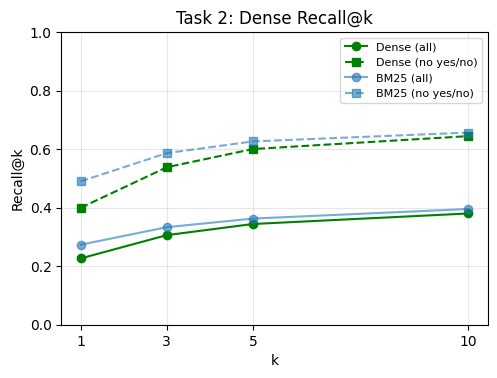

,question,gold,pred,F1
0,What is polar bear's skin color?,white or cream,Black,0.00
1,Is Canada a member of the OECD?,Yes.,Yes,1.00
2,Did Abraham Lincoln live in the Frontier?,Yes,Yes,1.00
3,When was Lee Kuan Yew prime minister of Singapore?,1959,1959 to 1990,0.50
4,What are the two subfamilies of the Native Ghanaian languages?,Kwa and Gur,Kwa and Gur,1.00
5,What positions Ford played in the school football team?,Center and linebacker,center and linebacker,1.00
6,Is the capital city Oslo?,no,No,1.00
7,Did Mainland Nova Scotia not come under British rule with the Treaty of Utre...,no!,yes,0.00
8,What is the national language of Singapore?,The national language of Singapore is Malay.,Malay,0.29
9,Was John Calvin Coolidge Jr. was born in Las Vegas?,No,No,1.00


In [13]:
plt.figure(figsize=(5.5, 3.8))
plt.plot(KS, [recall_at_k(dense_ranked, answers, k) for k in KS], marker='o', color='green',
         label='Dense (all)')
plt.plot(KS, [recall_at_k(sub(dense_ranked, keep), sub(answers, keep), k) for k in KS],
         marker='s', ls='--', color='green', label='Dense (no yes/no)')
if t1 is not None:
    plt.plot(KS, [recall_at_k(t1['bm25_ranked'], answers, k) for k in KS], marker='o',
             color='tab:blue', alpha=.6, label='BM25 (all)')
    plt.plot(KS, [recall_at_k(sub(t1['bm25_ranked'], keep), sub(answers, keep), k) for k in KS],
             marker='s', ls='--', color='tab:blue', alpha=.6, label='BM25 (no yes/no)')
plt.xlabel('k'); plt.ylabel('Recall@k'); plt.title('Task 2: Dense Recall@k')
plt.xticks(KS); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend(fontsize=8)
plt.savefig(f'{OUT}/task2_recall.png', dpi=150, bbox_inches='tight'); plt.show()

sample = random.sample(range(len(questions)), min(10, len(questions)))
pd.set_option('display.max_colwidth', 80)
pd.DataFrame({'question': sub(questions, sample), 'gold': sub(answers, sample),
              'pred': sub(task2_preds, sample),
              'F1': [round(f1_score(task2_preds[i], answers[i]), 2) for i in sample]})

## 11. Saving the results
`task2_results.json` contains everything Task 3 needs:
- the dense top-100 ranking for every question;
- the generated answers and the metric table;
- the dataset ids of the ranked passages;
- the generation settings (model, system prompt, token limits, batch size, dataset revision).

Task 3 reuses these settings so that, when it generates answers from the hybrid ranking, only the retriever changes.

In [14]:
if QUICK_TEST:
    print('QUICK_TEST is on - results NOT saved. Set QUICK_TEST = False and run all.')
else:
    with open(f'{OUT}/task2_results.json', 'w') as f:
        json.dump({'dense_ranked': dense_ranked,
                   'preds': task2_preds,
                   'llm': LLM_NAME,
                   'metrics': task2_table.to_dict(orient='records'),
                   'passage_ids': passage_ids,           # dataset ids of the ranked positions
                   'config': {'embed_model': EMBED_MODEL, 'top_k': TOP_K,
                              'passage_max_tokens': PASSAGE_MAX_TOKENS,
                              'max_new_tokens': MAX_NEW_TOKENS, 'decoding': 'greedy',
                              'batch_size': BATCH_SIZE, 'dataset_revision': DATASET_REVISION,
                              'system_prompt': SYSTEM, 'keep_n': KEEP_N}}, f)
    print('saved', f'{OUT}/task2_results.json')

saved outputs/task2_results.json


## 12. Discussion

**Overall.** Dense retrieval combined with `Qwen2.5-1.5B-Instruct` reaches **EM 0.564 and F1 0.671** on all 918 questions, compared with EM 0.019 and F1 0.055 for the Task 1 baseline. On the 498 non-yes/no questions it reaches EM 0.313 and F1 0.505 (Task 1: 0.034 and 0.099). Both notebooks use identical text cleaning and metric code, so these numbers are directly comparable.

**Retrieval did not improve.** On the non-yes/no questions, MiniLM's answer-string recall is *below* BM25 at every k:

| | R@1 | R@3 | R@5 | R@10 |
|---|---|---|---|---|
| BM25 (Task 1) | 0.490 | 0.586 | 0.627 | 0.657 |
| Dense (Task 2) | 0.400 | 0.538 | 0.600 | 0.645 |

Many questions name specific entities (people, places, dates), which exact word matching handles well. MiniLM also tends to rank very short, caption-like passages first (e.g. *"Young Abraham Lincoln"*, for 93 questions), and it only reads the first 256 word pieces of the 83 longest passages.

The two retrievers are, however, **complementary**: their top-5 lists share only about 34% of their passages. BM25 finds the answer for 40 factual questions that dense retrieval misses, while dense retrieval finds 27 that BM25 misses. This is what Task 3 builds on.

**The gain comes from the reader.** When the gold answer is in the top-5 passages, the LLM answers correctly (F1 ≥ 0.5) for 71.9% of the questions (215 of 299). Its answers are short (2.2 words on average vs 3.2 for the gold answers), so EM is meaningful. F1 > EM mostly reflects partial matches such as *"1959 to 1990"* vs *"1959"*, or *"Malay"* vs a full-sentence gold answer. Unlike the extractive reader, it can also answer yes/no questions.

**Yes/no questions.**
- The model gives the right yes/no answer for 87.9% of the 420 yes/no questions. EM is 0.862 because 10 gold answers are full sentences such as *"Yes, they do."*.
- Answering "yes" every time would already score 81.0%, so the real gain is modest.
- The model says "yes" to 24 of the 80 questions whose answer is "no".
- The yes/no instruction in the prompt also leaks into 20 factual questions that were answered "yes" or "no".

**Limitations.** EM penalises formatting (*"7"* vs *"seven"*), and some gold labels in the dataset are noisy. The 48 answers that are correct although the gold string is not in the top-5 passages are mostly paraphrases: the exact gold string occurs nowhere in the corpus for 39 of them. They reflect a limitation of answer-string Recall@k rather than the model answering from memory. Whether the generated answers are really supported by the retrieved passages is measured by the groundedness check in Task 3.

**Conclusion.** Replacing the extractive reader with an LLM raises EM about 30 times and F1 about 12 times over the baseline, even though the dense retriever is weaker than BM25 on this dataset. The generator, not the retriever, makes the difference. The complementary strengths of the two retrievers suggest combining them, which we do in Task 3.

## 13. References
- P. Lewis, E. Perez, A. Piktus et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.* NeurIPS. arXiv:2005.11401
- V. Karpukhin, B. Oğuz, S. Min et al. (2020). *Dense Passage Retrieval for Open-Domain Question Answering.* EMNLP. (answer-string Recall@k)
- N. Reimers and I. Gurevych (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks.* EMNLP-IJCNLP.
- W. Wang, F. Wei, L. Dong et al. (2020). *MiniLM: Deep Self-Attention Distillation for Task-Agnostic Compression of Pre-Trained Transformers.* NeurIPS.
- J. Johnson, M. Douze and H. Jégou (2019). *Billion-scale Similarity Search with GPUs.* IEEE Transactions on Big Data. (FAISS)
- Qwen Team (2024). *Qwen2.5 Technical Report.* arXiv:2412.15115
- P. Rajpurkar, J. Zhang, K. Lopyrev and P. Liang (2016). *SQuAD: 100,000+ Questions for Machine Comprehension of Text.* EMNLP. (EM/F1 and answer normalisation)